In [1]:
!pip install pandas numpy matplotlib seaborn scikit-learn

In [2]:
from google.colab import files
uploaded = files.upload()

Saving WA_Fn-UseC_-Telco-Customer-Churn.csv to WA_Fn-UseC_-Telco-Customer-Churn.csv


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

print("Dataset Shape:", df.shape)
print("\nFirst 5 Rows:")
display(df.head())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (7043, 21)

First 5 Rows:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  70

In [4]:
# Remove duplicate records
df = df.drop_duplicates().copy()

# Convert TotalCharges to numeric
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
)

# Check missing values after conversion
print("Missing values before handling:")
print(df.isnull().sum().sum())

# Fill missing numeric values with median
df["TotalCharges"] = df["TotalCharges"].fillna(
    df["TotalCharges"].median()
)

print("\nDataset shape after cleaning:", df.shape)
print("Remaining missing values:", df.isnull().sum().sum())

Missing values before handling:
11

Dataset shape after cleaning: (7043, 21)
Remaining missing values: 0


Customer Churn Rate: 26.54%


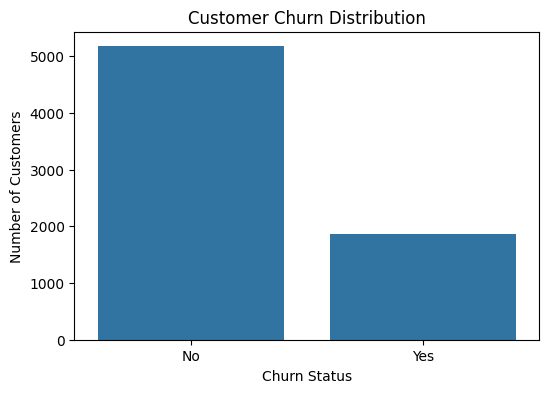

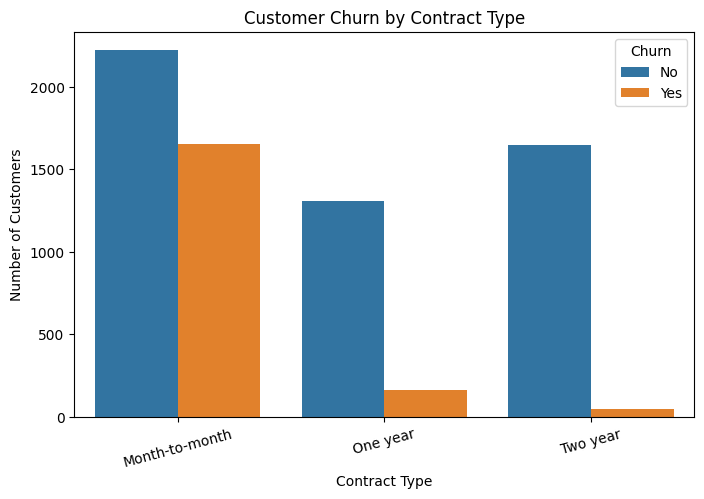

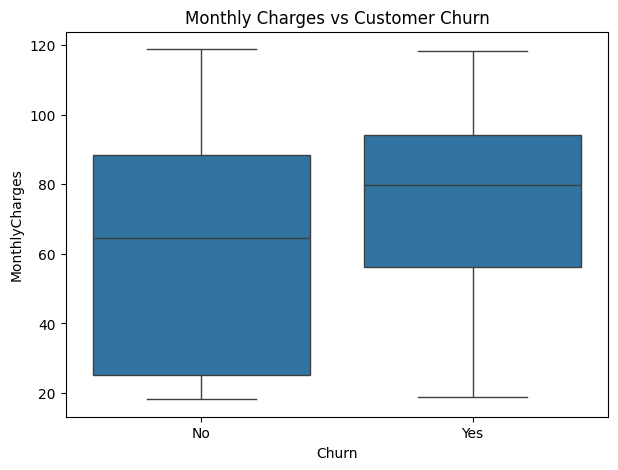

In [5]:

# Calculate churn percentage
churn_rate = (df["Churn"] == "Yes").mean() * 100

print(f"Customer Churn Rate: {churn_rate:.2f}%")

# Graph 1: Churn distribution
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Churn")
plt.title("Customer Churn Distribution")
plt.xlabel("Churn Status")
plt.ylabel("Number of Customers")
plt.show()

# Graph 2: Churn by contract type
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="Contract", hue="Churn")
plt.title("Customer Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")
plt.xticks(rotation=15)
plt.show()

# Graph 3: Monthly charges by churn
plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x="Churn", y="MonthlyCharges")
plt.title("Monthly Charges vs Customer Churn")
plt.show()

In [6]:

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# Separate features and target
X = df.drop(columns=["Churn", "customerID"])
y = df["Churn"].map({"No": 0, "Yes": 1})

# Identify numeric and categorical columns
numeric_cols = X.select_dtypes(include=np.number).columns.tolist()
categorical_cols = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

# Preprocess data
preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), numeric_cols),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_cols)
])

# Split into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Create and train model
model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

model.fit(X_train, y_train)

# Make predictions
predictions = model.predict(X_test)

print("Model Accuracy:",
      round(accuracy_score(y_test, predictions) * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_test, predictions, target_names=["No Churn", "Churn"]
))

Model Accuracy: 80.55 %

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.85      0.89      0.87      1035
       Churn       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



For my side extra

In [7]:

!pip -q install pandas numpy matplotlib seaborn scikit-learn joblib

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import joblib

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    classification_report, RocCurveDisplay
)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

print("Libraries loaded successfully!")

Libraries loaded successfully!


In [8]:

from google.colab import files
uploaded = files.upload()

df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

# Clean data types
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
)

# Remove duplicate rows
df = df.drop_duplicates().copy()

# Fill missing TotalCharges using median
df["TotalCharges"] = df["TotalCharges"].fillna(
    df["TotalCharges"].median()
)

print("Rows and columns:", df.shape)
print("Duplicate rows:", df.duplicated().sum())
print("Missing values:", df.isnull().sum().sum())

display(df.head())
display(df.describe(include="all").T)

Saving WA_Fn-UseC_-Telco-Customer-Churn.csv to WA_Fn-UseC_-Telco-Customer-Churn (1).csv
Rows and columns: (7043, 21)
Duplicate rows: 0
Missing values: 0


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,3186-AJIEK,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


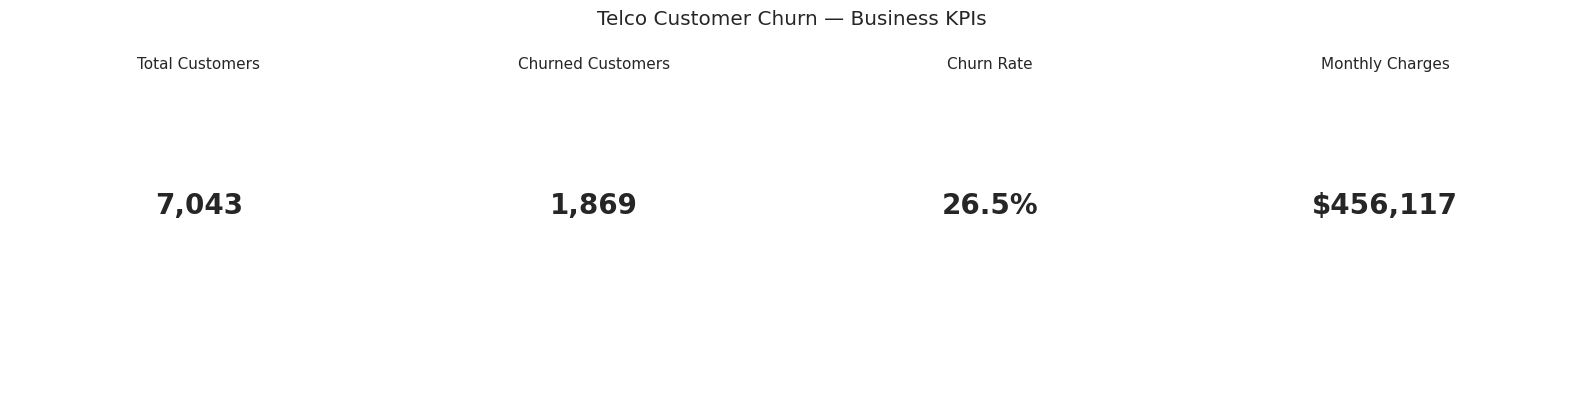

In [10]:
total_customers = len(df)
churned = (df["Churn"] == "Yes").sum()
retained = (df["Churn"] == "No").sum()
churn_rate = churned / total_customers * 100
monthly_revenue = df["MonthlyCharges"].sum()

fig, axes = plt.subplots(1, 4, figsize=(16, 4))

kpis = [
    ("Total Customers", f"{total_customers:,}"),
    ("Churned Customers", f"{churned:,}"),
    ("Churn Rate", f"{churn_rate:.1f}%"),
    ("Monthly Charges", f"${monthly_revenue:,.0f}")
]

for ax, (label, value) in zip(axes, kpis):
    ax.text(0.5, 0.58, value, ha="center",
            va="center", fontsize=20, fontweight="bold")
    ax.set_title(label, fontsize=11)
    ax.axis("off")

plt.suptitle("Telco Customer Churn — Business KPIs")
plt.tight_layout()
plt.show()

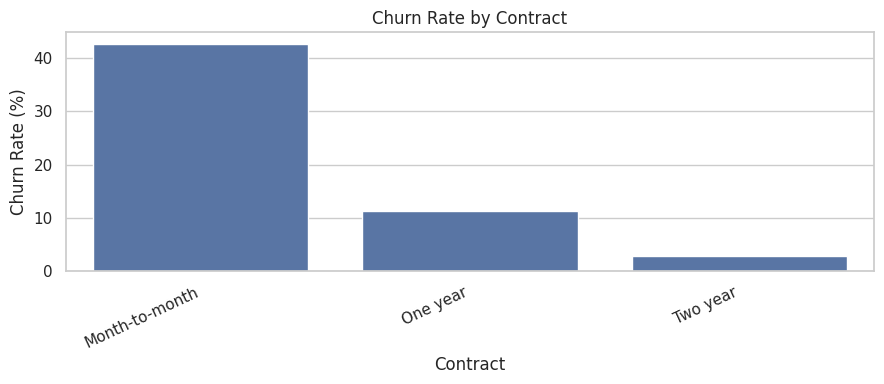

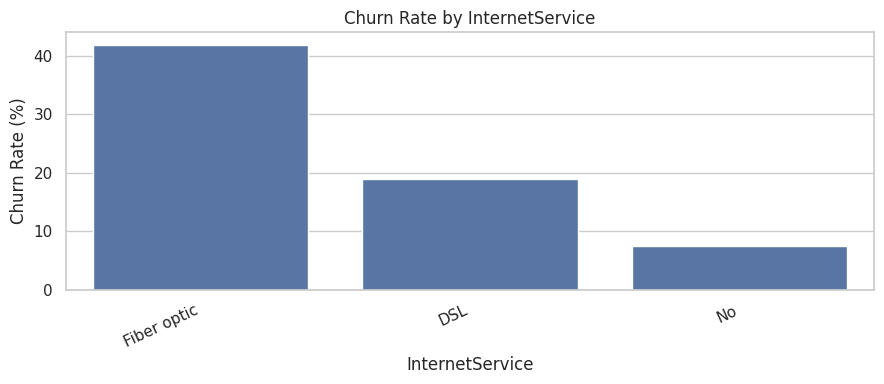

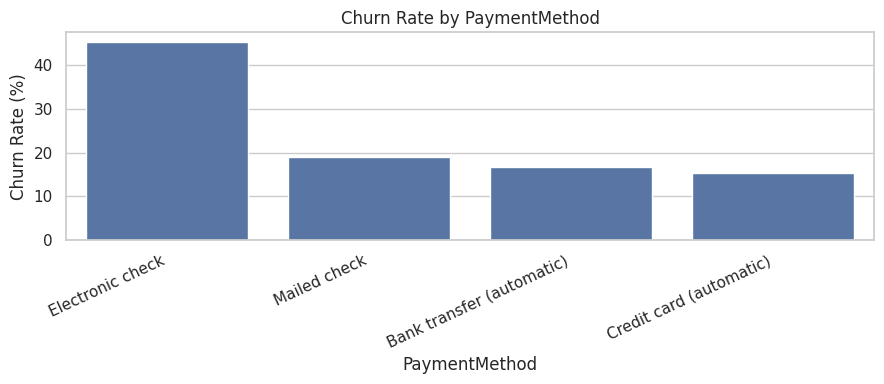

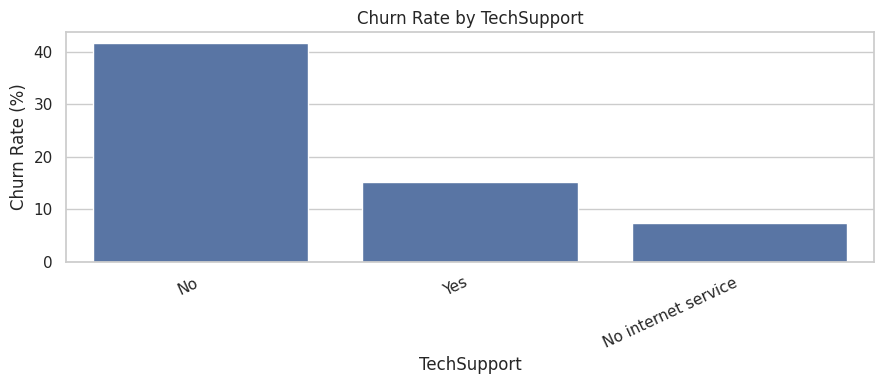

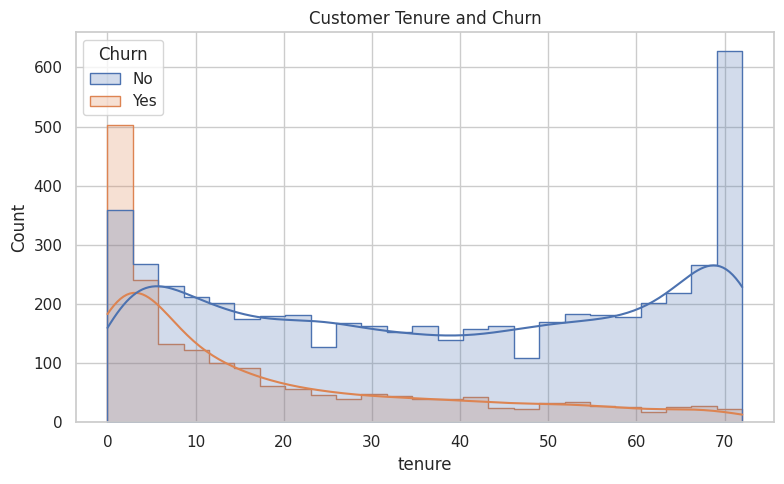

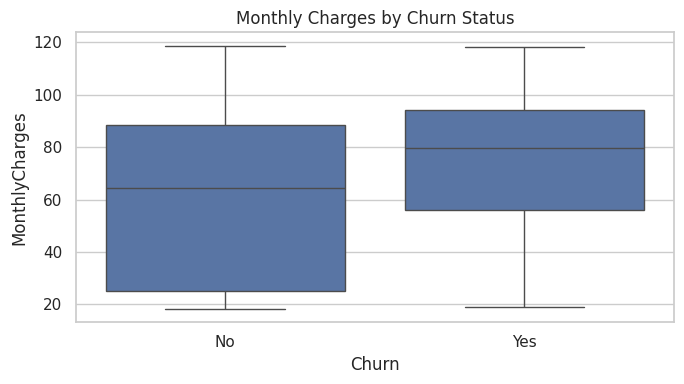

In [11]:

# Churn rate by category
def plot_churn_rate(column):
    rates = (
        df.groupby(column, dropna=False)["Churn"]
        .apply(lambda s: (s == "Yes").mean() * 100)
        .sort_values(ascending=False)
    )

    plt.figure(figsize=(9, 4))
    sns.barplot(x=rates.index.astype(str), y=rates.values)
    plt.title(f"Churn Rate by {column}")
    plt.ylabel("Churn Rate (%)")
    plt.xlabel(column)
    plt.xticks(rotation=25, ha="right")
    plt.tight_layout()
    plt.show()

plot_churn_rate("Contract")
plot_churn_rate("InternetService")
plot_churn_rate("PaymentMethod")
plot_churn_rate("TechSupport")

# Tenure comparison
plt.figure(figsize=(8, 5))
sns.histplot(
    data=df, x="tenure", hue="Churn",
    bins=25, kde=True, element="step"
)
plt.title("Customer Tenure and Churn")
plt.tight_layout()
plt.show()

# Monthly charges comparison
plt.figure(figsize=(7, 4))
sns.boxplot(data=df, x="Churn", y="MonthlyCharges")
plt.title("Monthly Charges by Churn Status")
plt.tight_layout()
plt.show()

,Customers,AverageMonthlyCharges,ChurnRate
TenureGroup,,,
0-12 Months,2186,56.10,47.44
13-24 Months,1024,61.36,28.71
25-48 Months,1594,65.93,20.39
49-72 Months,2239,73.95,9.51


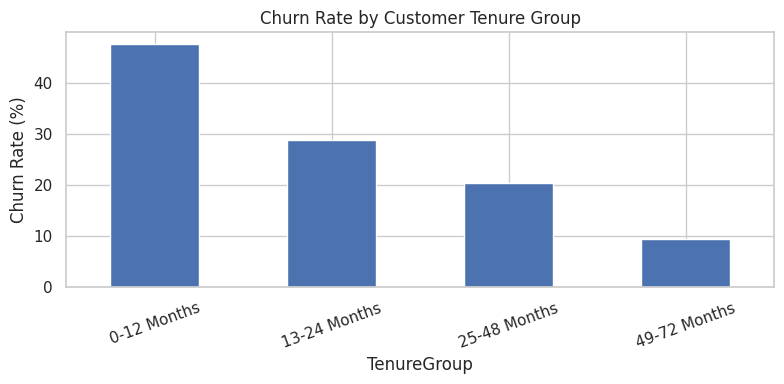

In [12]:

df["TenureGroup"] = pd.cut(
    df["tenure"],
    bins=[-1, 12, 24, 48, 72],
    labels=["0-12 Months", "13-24 Months",
            "25-48 Months", "49-72 Months"]
)

segment_analysis = (
    df.groupby("TenureGroup", observed=False)
    .agg(
        Customers=("customerID", "count"),
        AverageMonthlyCharges=("MonthlyCharges", "mean"),
        ChurnRate=("Churn", lambda x: (x == "Yes").mean() * 100)
    )
    .round(2)
)

display(segment_analysis)

segment_analysis["ChurnRate"].plot(
    kind="bar", figsize=(8, 4),
    title="Churn Rate by Customer Tenure Group",
    ylabel="Churn Rate (%)"
)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [13]:

# Prepare features and target
X = df.drop(columns=["customerID", "Churn"])
y = (df["Churn"] == "Yes").astype(int)

numeric_cols = X.select_dtypes(include=np.number).columns.tolist()
categorical_cols = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

# Preprocessing
preprocessor = ColumnTransformer([
    ("numeric", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), numeric_cols),

    ("categorical", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_cols)
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000, class_weight="balanced"
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )
}

trained_models = {}
results = []

for name, classifier in models.items():
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", classifier)
    ])

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_test)
    probabilities = pipeline.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    })

    trained_models[name] = pipeline

results_df = pd.DataFrame(results).set_index("Model")
display(results_df.round(3))

,Accuracy,Precision,Recall,F1 Score,ROC-AUC
Model,,,,,
Logistic Regression,0.732,0.497,0.791,0.611,0.842
Random Forest,0.776,0.572,0.623,0.597,0.834


Selected model: Logistic Regression

Classification Report:
              precision    recall  f1-score   support

    Retained       0.90      0.71      0.80      1035
     Churned       0.50      0.79      0.61       374

    accuracy                           0.73      1409
   macro avg       0.70      0.75      0.70      1409
weighted avg       0.80      0.73      0.75      1409



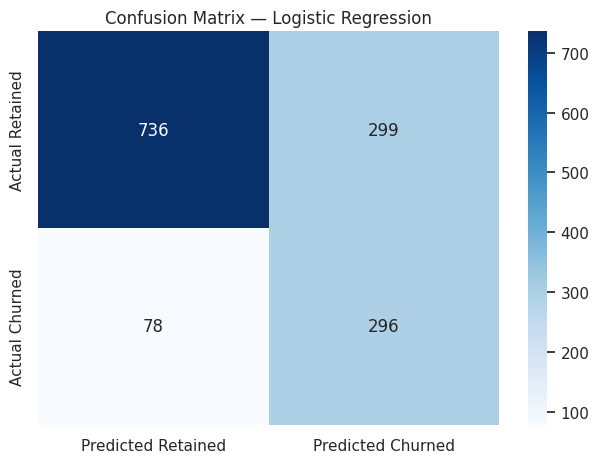

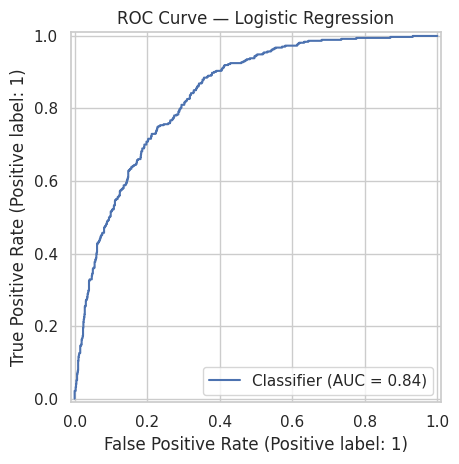

In [14]:

# Select the model with the highest ROC-AUC
best_name = results_df["ROC-AUC"].idxmax()
best_model = trained_models[best_name]

print("Selected model:", best_name)

predictions = best_model.predict(X_test)
probabilities = best_model.predict_proba(X_test)[:, 1]

print("\nClassification Report:")
print(classification_report(
    y_test, predictions,
    target_names=["Retained", "Churned"],
    zero_division=0
))

# Confusion matrix
cm = confusion_matrix(y_test, predictions)

sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Predicted Retained", "Predicted Churned"],
    yticklabels=["Actual Retained", "Actual Churned"]
)
plt.title(f"Confusion Matrix — {best_name}")
plt.tight_layout()
plt.show()

# ROC curve
RocCurveDisplay.from_predictions(y_test, probabilities)
plt.title(f"ROC Curve — {best_name}")
plt.tight_layout()
plt.show()

,Feature,Importance
1,numeric__tenure,1.0346
38,categorical__Contract_Two year,0.8437
16,categorical__InternetService_Fiber optic,0.7112
36,categorical__Contract_Month-to-month,0.7003
15,categorical__InternetService_DSL,0.6241
2,numeric__MonthlyCharges,0.5861
46,categorical__TenureGroup_13-24 Months,0.3828
48,categorical__TenureGroup_49-72 Months,0.3498
35,categorical__StreamingMovies_Yes,0.2820
19,categorical__OnlineSecurity_No internet service,0.2737


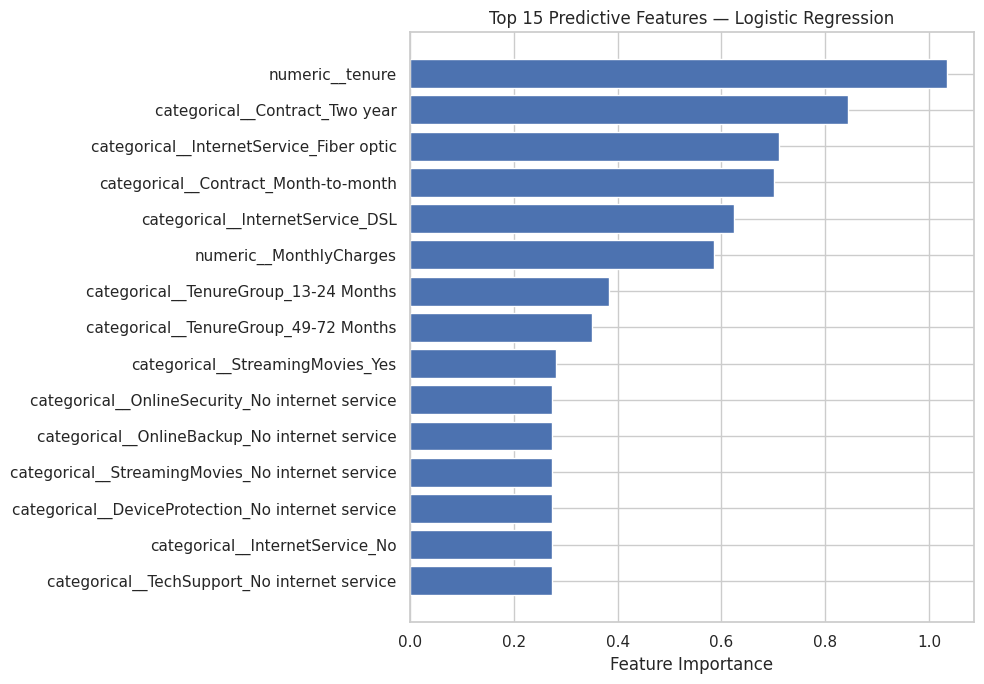

In [15]:

classifier = best_model.named_steps["classifier"]
feature_names = best_model.named_steps[
    "preprocessor"
].get_feature_names_out()

if hasattr(classifier, "feature_importances_"):
    importance = classifier.feature_importances_
else:
    importance = np.abs(classifier.coef_[0])

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
}).sort_values("Importance", ascending=False)

display(importance_df.head(15).round(4))

top_features = importance_df.head(15).sort_values("Importance")

plt.figure(figsize=(10, 7))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.title(f"Top 15 Predictive Features — {best_name}")
plt.xlabel("Feature Importance")
plt.tight_layout()
plt.show()

In [16]:

risk_report = df.loc[X_test.index, [
    "customerID", "Contract", "tenure",
    "MonthlyCharges", "Churn"
]].copy()

risk_report["ActualChurn"] = risk_report["Churn"]
risk_report["ChurnProbability"] = probabilities
risk_report["PredictedChurn"] = np.where(
    probabilities >= 0.5, "Yes", "No"
)

risk_report["RiskLevel"] = pd.cut(
    probabilities,
    bins=[-0.001, 0.30, 0.60, 1.001],
    labels=["Low", "Medium", "High"]
)

risk_report = risk_report.sort_values(
    "ChurnProbability", ascending=False
)

display(risk_report.head(15))

risk_report.to_csv("churn_risk_report.csv", index=False)
print("Saved: churn_risk_report.csv")

,customerID,Contract,tenure,MonthlyCharges,Churn,ActualChurn,ChurnProbability,PredictedChurn,RiskLevel
3380,5178-LMXOP,Month-to-month,1,95.10,Yes,Yes,0.952392,Yes,High
2631,6861-XWTWQ,Month-to-month,7,99.25,Yes,Yes,0.942687,Yes,High
6866,0295-PPHDO,Month-to-month,1,95.45,Yes,Yes,0.942648,Yes,High
6894,1400-MMYXY,Month-to-month,3,105.90,Yes,Yes,0.940767,Yes,High
6365,8884-ADFVN,Month-to-month,7,101.95,Yes,Yes,0.939946,Yes,High
2797,6023-YEBUP,Month-to-month,3,100.95,Yes,Yes,0.938116,Yes,High
3727,9057-SIHCH,Month-to-month,3,96.60,Yes,Yes,0.935908,Yes,High
4585,1069-XAIEM,Month-to-month,1,85.05,Yes,Yes,0.935902,Yes,High
3346,2545-EBUPK,Month-to-month,2,84.05,No,No,0.935030,Yes,High
4039,8161-QYMTT,Month-to-month,7,94.10,No,No,0.932286,Yes,High


Saved: churn_risk_report.csv


In [17]:

print("BUSINESS INSIGHTS AND RECOMMENDATIONS")
print("=" * 45)

contract_rates = (
    df.groupby("Contract")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .sort_values(ascending=False)
)

payment_rates = (
    df.groupby("PaymentMethod")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .sort_values(ascending=False)
)

print(f"\nOverall churn rate: {churn_rate:.2f}%")

print("\nChurn rate by contract:")
display(contract_rates.round(2).rename("Churn Rate (%)"))

print("\nChurn rate by payment method:")
display(payment_rates.round(2).rename("Churn Rate (%)"))

print("\nRECOMMENDATIONS:")

print("1. Investigate contract types with the highest churn.")
print("2. Review early-tenure customer onboarding and support.")
print("3. Evaluate service quality and support availability.")
print("4. Test retention offers for customers at high predicted risk.")
print("5. Monitor recall, precision and ROC-AUC after each model update.")

BUSINESS INSIGHTS AND RECOMMENDATIONS

Overall churn rate: 26.54%

Churn rate by contract:


,Churn Rate (%)
Contract,
Month-to-month,42.71
One year,11.27
Two year,2.83



Churn rate by payment method:


,Churn Rate (%)
PaymentMethod,
Electronic check,45.29
Mailed check,19.11
Bank transfer (automatic),16.71
Credit card (automatic),15.24



RECOMMENDATIONS:
1. Investigate contract types with the highest churn.
2. Review early-tenure customer onboarding and support.
3. Evaluate service quality and support availability.
4. Test retention offers for customers at high predicted risk.
5. Monitor recall, precision and ROC-AUC after each model update.


In [18]:
# Save the trained model
joblib.dump(best_model, "telco_churn_model.pkl")

# Save model comparison results
results_df.to_csv("model_comparison.csv")

# Save feature importance
importance_df.to_csv("feature_importance.csv", index=False)

print("All project outputs saved successfully!")

# Download the main output files
from google.colab import files

files.download("churn_risk_report.csv")
files.download("model_comparison.csv")
files.download("feature_importance.csv")
files.download("telco_churn_model.pkl")

All project outputs saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [19]:
requirements = """pandas
numpy
matplotlib
seaborn
scikit-learn
joblib
"""

with open("requirements.txt", "w") as f:
    f.write(requirements)

from google.colab import files
files.download("requirements.txt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>